In [1]:
# Previsione dei noleggi

# Importiamo le librerie per il modello e per valutarne gli errori.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from pathlib import Path

MUTED = '#647280'
REGISTERED = '#0072B2'
CASUAL = '#E69F00'
NEUTRAL = '#86939E'
DARK = '#253342'
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Creiamo la cartella dei grafici.
OUT=Path('../output/figures');OUT.mkdir(parents=True,exist_ok=True)

# Apriamo i dati orari e ordiniamoli cronologicamente.
hour=pd.read_csv('../data/processed/bike_hour_clean.csv',parse_dates=['dteday'])
hour['timestamp']=hour['dteday']+pd.to_timedelta(hour['hr'],unit='h')
hour=hour.sort_values('timestamp')

# Usiamo soltanto calendario e meteo: non includiamo le colonne che sommate danno il target.
features=['hr','weekday','workingday','holiday','mnth','yr',
          'weathersit','temp','hum','windspeed']

# Tenendo intere le giornate, usiamo il primo 80% per allenare e il resto per testare.
unique_days=np.sort(hour['dteday'].unique())
split_day=pd.Timestamp(unique_days[int(len(unique_days)*0.80)])
train=hour[hour['dteday']<split_day].copy()
test=hour[hour['dteday']>=split_day].copy()
X_train=train[features];y_train=train['cnt']
X_test=test[features];y_test=test['cnt']
print('Train:',len(train),'hours; test:',len(test),'hours; test starts:',split_day.date())

# Prepariamo una baseline: media storica per ora e tipo di giornata.
ref=train.groupby(['hr','workingday'])['cnt'].mean()
fallback=train['cnt'].mean()
baseline=np.array([
    ref.get((int(h),int(w)), fallback)
    for h,w in zip(test['hr'],test['workingday'])
])

# Alleniamo Random Forest sui soli dati di training.
model=RandomForestRegressor(n_estimators=160,min_samples_leaf=4,
                            max_features=.85,n_jobs=1,random_state=42)
model.fit(X_train,y_train)
pred=model.predict(X_test)

# Calcoliamo MAE, RMSE e R² per baseline e modello sullo stesso periodo.
def metrics(y,yp):
    return {'MAE':mean_absolute_error(y,yp),
            'RMSE':np.sqrt(mean_squared_error(y,yp)),
            'R²':r2_score(y,yp)}

# Mostriamo il confronto numerico delle prestazioni.
quality=pd.DataFrame({'Hourly mean baseline':metrics(y_test,baseline),
                      'Random Forest':metrics(y_test,pred)}).T
print('OUT-OF-TIME TEST PERFORMANCE')
display(quality.round(2))

Train: 13891 hours; test: 3488 hours; test starts: 2012-08-07


OUT-OF-TIME TEST PERFORMANCE


,MAE,RMSE,R²
Hourly mean baseline,101.52,144.89,0.57
Random Forest,47.63,73.07,0.89


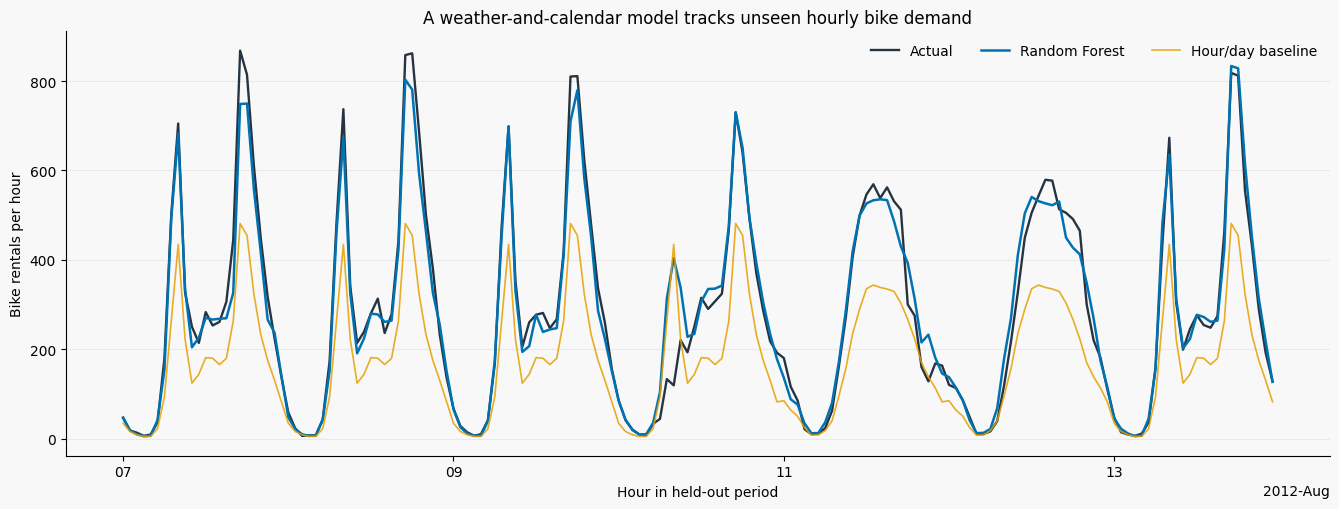

In [2]:
# Affianchiamo valori effettivi, previsione e baseline nel periodo di test.
plot_test=test.copy()
plot_test['rf_prediction']=pred
plot_test['baseline']=baseline

# Selezioniamo una sola settimana per rendere il grafico leggibile.
week=plot_test.iloc[:7*24]

# Confrontiamo le tre curve usando la stessa scala.
fig,ax=plt.subplots(figsize=(13.5,5.2))
ax.plot(week['timestamp'],week['cnt'],color=DARK,lw=1.7,label='Actual')
ax.plot(week['timestamp'],week['rf_prediction'],color=REGISTERED,lw=1.8,label='Random Forest')
ax.plot(week['timestamp'],week['baseline'],color=CASUAL,lw=1.2,alpha=.85,label='Hour/day baseline')
ax.set(title='A weather-and-calendar model tracks unseen hourly bike demand',
       xlabel='Hour in held-out period',ylabel='Bike rentals per hour')
ax.grid(axis='y', alpha=0.2); ax.set_axisbelow(True);ax.legend(ncol=3,frameon=False)
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.tick_params(axis='x', rotation=0)
fig.tight_layout();fig.savefig(OUT/'RQ10A_forecast_vs_actual.png',dpi=200,bbox_inches='tight');plt.show()

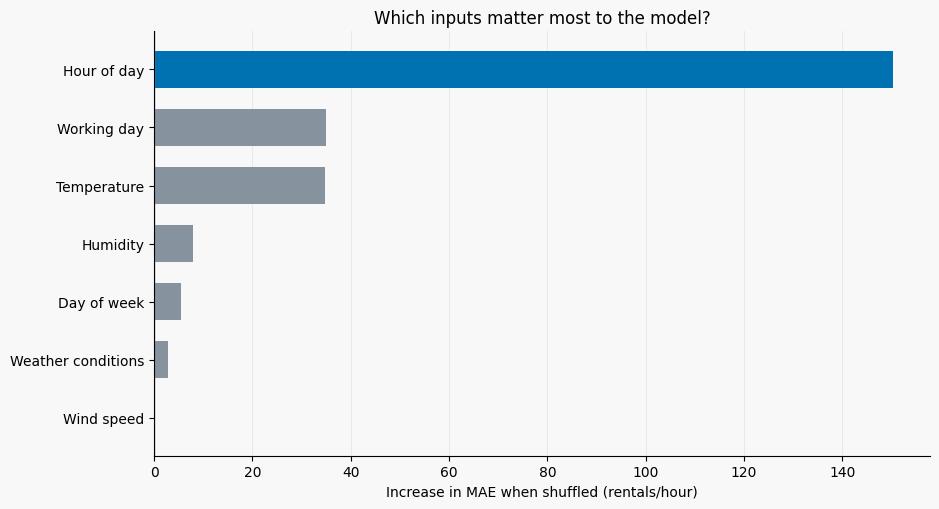

hr            150.3
workingday     35.0
temp           34.8
hum             7.9
weekday         5.5
weathersit      2.7
windspeed       0.2
holiday         0.0
mnth            0.0
yr              0.0
dtype: float64


In [3]:
# Campioniamo al massimo 1800 ore del test per accelerare la spiegazione.
sample_idx=X_test.sample(n=min(1800,len(X_test)),random_state=42).index

# Misuriamo quanto peggiora il MAE quando mescoliamo una variabile.
permutation=permutation_importance(
    model,X_test.loc[sample_idx],y_test.loc[sample_idx],
    scoring='neg_mean_absolute_error',n_repeats=5,random_state=42,n_jobs=1
)

# Ordiniamo l’importanza delle variabili.
imp=pd.Series(permutation.importances_mean,index=features).sort_values()

# Mostriamo le sette variabili più importanti, con nomi leggibili.
feature_names = {
    'hr': 'Hour of day', 'workingday': 'Working day', 'temp': 'Temperature',
    'hum': 'Humidity', 'weekday': 'Day of week', 'weathersit': 'Weather conditions',
    'windspeed': 'Wind speed', 'holiday': 'Holiday', 'mnth': 'Month', 'yr': 'Year'
}
important = imp.nlargest(7).sort_values()
labels_plot = [feature_names[name] for name in important.index]
colors_plot = [REGISTERED if name == imp.idxmax() else NEUTRAL
               for name in important.index]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.barh(labels_plot, important.values, color=colors_plot, height=0.65)
ax.axvline(0, color=NEUTRAL, lw=1)
ax.set(title='Which inputs matter most to the model?',
       xlabel='Increase in MAE when shuffled (rentals/hour)', ylabel='')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUT/'RQ10B_permutation_importance.png', dpi=200, bbox_inches='tight')
plt.show()
print(imp.sort_values(ascending=False).round(1))